# Financial applications of quantum computing
### Investment portfolios with real instruments: from the efficient frontier to a quantum circuit

**XXX International School of Informatics · CACIC 2026 · Course 3: Foundations and Intuition of Quantum Computing**  
Juan Pablo Braña · CAETI, Universidad Abierta Interamericana

In this hands-on session we build investment portfolios with **real prices** of 12 well-known companies and walk the whole path, from classical theory to a quantum computer:

| Step | What we do | Where it runs |
|---|---|---|
| 1 | Download real prices | Yahoo Finance |
| 2 | Modern portfolio theory: the efficient frontier | classical computer |
| 3 | Parametric circuits: a knob that changes probabilities | quantum simulator |
| 4 | A quantum optimizer (VQE) picks a portfolio | quantum simulator |
| 5 | Our approach: a circuit that estimates the risk of each asset | quantum simulator |
| 6 | Why we do not start with Hadamard | quantum simulator |
| 7 | The same circuit on a quantum computer | IBM Quantum |
| 8 | Did it work? Evaluation on the 12 months after, and a new out-of-sample test | classical computer |

> **Where it comes from.** The method in section 5 is the one in the paper *A Parametric Quantum Circuit for Portfolio Risk Assessment at 110 Qubits* (Braña, Litterio, Fernández et al., QCQSE-Chile, JCC 2026), run with 110 assets and 110 qubits on an IBM computer. Here we use 12 assets so that everything fits on screen.
>
> **Disclaimer.** This is educational material. Nothing that follows is investment advice.

## 0. Setup

The notebook runs top to bottom in under a minute. Everything quantum runs on simulators, except section 7, which can send the circuit to a real IBM computer (optional).

**Interactive charts.** The two line charts, the one in section 1 and the one in section 8, can zoom: drag the mouse over an area to enlarge it and double-click to go back. Hovering shows the values of each curve. The legend works as a filter: one click hides or shows a curve and a double click leaves only that one. On GitHub they appear as a static image.

In [1]:
# On Google Colab, or if you are missing a package, uncomment the next line and run it once:
# %pip install -q qiskit qiskit-aer qiskit-ibm-runtime yfinance pylatexenc plotly

In [2]:
import json, os, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import minimize
from scipy.stats import spearmanr

from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 110, "font.size": 12, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------- Class configuration (try changing it) -----------------------
ASSETS = {   # ticker: (company, sector)
    "AAPL": ("Apple", "Technology"),               "MSFT": ("Microsoft", "Technology"),
    "AMZN": ("Amazon", "Technology"),              "NVDA": ("Nvidia", "Technology"),
    "TSLA": ("Tesla", "Consumer discretionary"),   "MELI": ("MercadoLibre", "Consumer discretionary"),
    "JPM":  ("JPMorgan", "Banks"),                 "BAC":  ("Bank of America", "Banks"),
    "XOM":  ("ExxonMobil", "Energy"),              "CVX":  ("Chevron", "Energy"),
    "KO":   ("Coca-Cola", "Consumer staples"),     "PEP":  ("PepsiCo", "Consumer staples"),
}
TICKERS   = list(ASSETS)
BENCHMARK = "SPY"                          # fund that tracks the S&P 500 index: "the market"
HISTORY   = ("2023-05-01", "2025-04-30")   # 24 months: the only thing the model may look at
FUTURE    = ("2025-05-01", "2026-04-30")   # the next 12 months: only for the final evaluation
SHOTS     = 4000                           # how many times each circuit is repeated (and measured)
SEED      = 7                              # so that the results repeat
DATA      = Path("data")                   # folder with the local copies

SECTOR_COLOR = {"Technology": "#1f6fb2", "Consumer discretionary": "#e07b00", "Banks": "#0f8b8d",
                "Energy": "#7b4ab8", "Consumer staples": "#b5477d"}
COLOR = {t: SECTOR_COLOR[sector] for t, (_, sector) in ASSETS.items()}
n = len(TICKERS)
print(f"{n} assets -> {n} qubits: {', '.join(TICKERS)}")

12 assets -> 12 qubits: AAPL, MSFT, AMZN, NVDA, TSLA, MELI, JPM, BAC, XOM, CVX, KO, PEP


In [3]:
# Presentation helper: makes a line chart interactive. You do not need to read it to follow the class.
def interactive_figure(fig, groups=None):
    """Shows a line chart made with matplotlib. If Plotly is installed, it makes the chart interactive:
    zoom into an area, values on hover and the legend as a curve filter.
    It also stores the static image: that is what GitHub shows, or what you get if Plotly is missing."""
    from IPython.core.pylabtools import print_figure
    static_image = lambda fmt: print_figure(fig, fmt, bbox_inches="tight", base64=True,
                                            pil_kwargs={"quality": 90})
    plt.close(fig)
    try:
        import plotly.graph_objects as go
        from matplotlib.colors import to_hex
        from matplotlib.dates import num2date
        ax, groups, interactive, with_dates = fig.axes[0], groups or {}, go.Figure(), False
        for line in ax.get_lines():
            label, x = line.get_gid() or line.get_label(), np.asarray(line.get_xdata())
            if label.startswith("_") or len(x) < 3:                   # unnamed or decorative lines
                continue
            if np.issubdtype(x.dtype, np.datetime64):                 # dates as milliseconds: they take less space
                x, with_dates = x.astype("datetime64[ms]").astype(float), True
            interactive.add_scatter(x=x, y=line.get_ydata(), name=label, mode="lines", opacity=line.get_alpha(),
                                    line=dict(color=to_hex(line.get_color()), width=1.4 * line.get_linewidth()),
                                    legendgroup=groups.get(label), legendgrouptitle_text=groups.get(label))
        for band in ax.patches:                                       # vertical bands (axvspan)
            edges = [band.get_x(), band.get_x() + band.get_width()]
            if with_dates:
                edges = [num2date(v).strftime("%Y-%m-%d") for v in edges]
            interactive.add_vrect(x0=edges[0], x1=edges[1], fillcolor=to_hex(band.get_facecolor()), line_width=0,
                                  opacity=band.get_alpha(), layer="below", annotation_text=band.get_label(),
                                  annotation_position="top left")
        x_axis = dict(title=ax.get_xlabel())
        if with_dates:                                                # month, day and year, also when zoomed in
            x_axis.update(type="date", hoverformat="%b %d, %Y",
                          tickformatstops=[dict(dtickrange=[None, "M1"], value="%b %d, %Y"),
                                           dict(dtickrange=["M1", None], value="%b %Y")])
        thousands = max(abs(v) for v in ax.get_ylim()) >= 1000        # large amounts: no decimals, with a thousands comma
        y_axis = dict(title=ax.get_ylabel(), type=ax.get_yscale(), hoverformat=",.0f" if thousands else ".1f",
                      tickformat=",.0f" if thousands else ("~g" if ax.get_yscale() == "log" else None))
        hint = dict(text="Click: hide or show<br>Double click: leave only one", font=dict(size=12, color="gray"))
        interactive.update_layout(title=ax.get_title(), xaxis=x_axis, yaxis=y_axis, template="plotly_white", height=600,
                                  font_size=14, margin=dict(t=60, b=40, l=60, r=20), hovermode="x unified",
                                  hoverlabel_namelength=-1, separators=".,",        # decimal point, thousands comma
                                  legend=dict(title=hint, groupclick="toggleitem", tracegroupgap=4))
        options = {"displaylogo": False, "displayModeBar": True, "showSendToCloud": False}    # no upload to the cloud
        output = {"application/vnd.plotly.v1+json": {**json.loads(interactive.to_json()), "config": options},
                  "image/jpeg": static_image("jpeg")}
    except Exception:                                             # without Plotly, or if anything fails, the static image remains
        output = {"image/png": static_image("png")}
    display(output, raw=True)

## 1. Real data from Yahoo Finance

We download each day's **adjusted closing price** (already corrected for dividends and stock splits).

We split time into two stretches:

- **HISTORY** (24 months): the only thing the models may look at to decide.
- **FUTURE** (the next 12 months): we keep it under lock and key and use it only at the end, to evaluate.

That separation is the golden rule: if we evaluate a portfolio with the same data we used to build it, we are fooling ourselves.

In [4]:
def download_prices(tickers, start, end, local_copy):
    """Adjusted closing prices from Yahoo Finance. If there is no connection, uses the local copy."""
    try:
        import yfinance as yf
        stop = (pd.Timestamp(end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
        # threads=False: downloads one asset at a time. In parallel, yfinance sometimes fails the first time it is used.
        px = yf.download(tickers, start=start, end=stop, auto_adjust=True, progress=False, threads=False)["Close"]
        px = px[tickers].dropna()
        assert len(px) > 200, "incomplete download"
        source = "Yahoo Finance (live download)"
        if not local_copy.exists():                        # we keep a copy to work offline
            local_copy.parent.mkdir(parents=True, exist_ok=True)
            px.to_csv(local_copy)
    except Exception as error:
        if not local_copy.exists():
            raise RuntimeError("Could not download the data and there is no local copy at " + str(local_copy)) from error
        px = pd.read_csv(local_copy, index_col=0, parse_dates=True)[tickers]
        source = f"local copy {local_copy} (no connection to Yahoo Finance)"
    return px, source

prices, source = download_prices(TICKERS + [BENCHMARK], "2023-04-25", FUTURE[1], DATA / "yahoo_prices.csv")
print("Source:", source)
print(f"{prices.shape[0]} trading days, from {prices.index[0].date()} to {prices.index[-1].date()}")
prices.tail(3).round(2)

Source: Yahoo Finance (live download)
757 trading days, from 2023-04-25 to 2026-04-30


Ticker,AAPL,MSFT,AMZN,NVDA,TSLA,MELI,JPM,BAC,XOM,CVX,KO,PEP,SPY
Date,,,,,,,,,,,,,
2026-04-28,270.02,426.69,259.70,212.68,376.02,1791.99,308.51,52.12,147.65,183.51,77.39,153.03,708.10
2026-04-29,269.48,421.93,263.04,208.77,372.80,1767.02,306.33,52.34,151.68,187.27,77.90,152.05,707.99
2026-04-30,270.66,405.35,265.06,199.11,381.63,1792.63,310.28,52.91,151.35,188.33,77.79,155.18,715.04


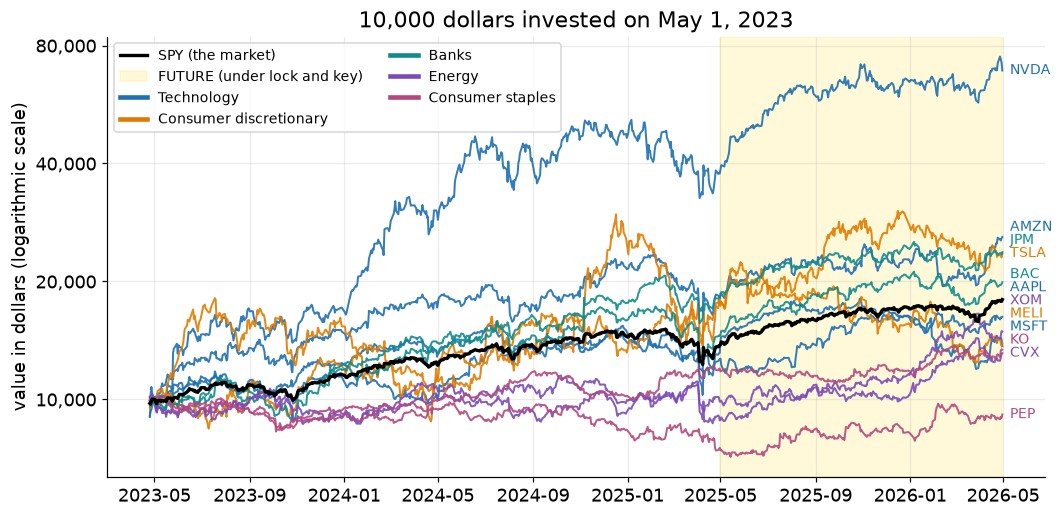

In [5]:
# Growth of 10,000 dollars invested in each asset at the start of HISTORY (logarithmic scale)
investment = prices / prices.loc[HISTORY[0]:].iloc[0] * 10_000
fig, ax = plt.subplots(figsize=(11, 5.2))
for t in TICKERS:
    ax.plot(investment[t], color=COLOR[t], lw=1.3, alpha=0.9, gid=t)     # gid: name of the interactive curve
height = 0                                               # labels at the end of each line, without overlapping
for t in investment[TICKERS].iloc[-1].sort_values().index:
    height = max(investment[t].iloc[-1], height * 1.08)
    ax.annotate(t, (investment.index[-1], height), xytext=(5, 0), textcoords="offset points", fontsize=9, color=COLOR[t], va="center")
ax.plot(investment[BENCHMARK], color="black", lw=2.2, label="SPY (the market)")
ax.axvspan(pd.Timestamp(FUTURE[0]), prices.index[-1], color="gold", alpha=0.15, label="FUTURE (under lock and key)")
ax.set_yscale("log"); ax.minorticks_off()
ax.set_yticks([5_000, 10_000, 20_000, 40_000, 80_000]); ax.set_yticklabels(["5,000", "10,000", "20,000", "40,000", "80,000"])
ax.set_title("10,000 dollars invested on May 1, 2023"); ax.set_ylabel("value in dollars (logarithmic scale)")
for sector, color in SECTOR_COLOR.items():
    ax.plot([], [], color=color, lw=3, label=sector)
ax.legend(fontsize=9, ncol=2, loc="upper left")
interactive_figure(fig, groups={t: sector for t, (_, sector) in ASSETS.items()})

**From prices to returns.** The daily return is how much the price changed from one day to the next. With the HISTORY returns we compute, for each asset, the two numbers that all of portfolio theory uses:

- **annual return**: how much it gained per year on average;
- **annual volatility**: how much the price shakes. It is the classic measure of **risk**.

In [6]:
returns = np.log(prices / prices.shift(1)).dropna()               # each day's (logarithmic) return
hist_returns = returns.loc[HISTORY[0]:HISTORY[1], TICKERS]        # what the models may look at

mu  = hist_returns.mean() * 252           # average annual return (252 trading days per year)
cov = hist_returns.cov() * 252            # annualized covariances: how they move together
vol = pd.Series(np.sqrt(np.diag(cov)), index=TICKERS)

summary = pd.DataFrame({"company": [ASSETS[t][0] for t in TICKERS], "sector": [ASSETS[t][1] for t in TICKERS],
                        "annual return": mu, "annual volatility": vol})
print(f"HISTORY: {len(hist_returns)} days of returns")
summary.sort_values("annual volatility").style.format({"annual return": "{:+.1%}", "annual volatility": "{:.1%}"})

HISTORY: 502 days of returns


,company,sector,annual return,annual volatility
KO,Coca-Cola,Consumer staples,+9.2%,14.9%
PEP,PepsiCo,Consumer staples,-14.1%,18.0%
XOM,ExxonMobil,Energy,-2.3%,22.8%
MSFT,Microsoft,Technology,+13.4%,22.8%
CVX,Chevron,Energy,-6.6%,23.3%
JPM,JPMorgan,Banks,+31.1%,23.4%
BAC,Bank of America,Banks,+18.3%,26.6%
AAPL,Apple,Technology,+11.8%,26.7%
AMZN,Amazon,Technology,+28.1%,31.2%
MELI,MercadoLibre,Consumer discretionary,+30.2%,39.3%


## 2. Modern portfolio theory (Markowitz, 1952)

The idea that earned Harry Markowitz the Nobel Prize: **it is not enough to look at each asset separately; what matters is how they move together**.

If two assets do not rise and fall at the same time, combining them makes the shakes partly cancel out. That is **diversifying**: the portfolio can have less risk than any of its components.

On the left, each asset by its risk and its return. On the right, the **correlation**: 1 means they move the same way, 0 that they have nothing to do with each other.

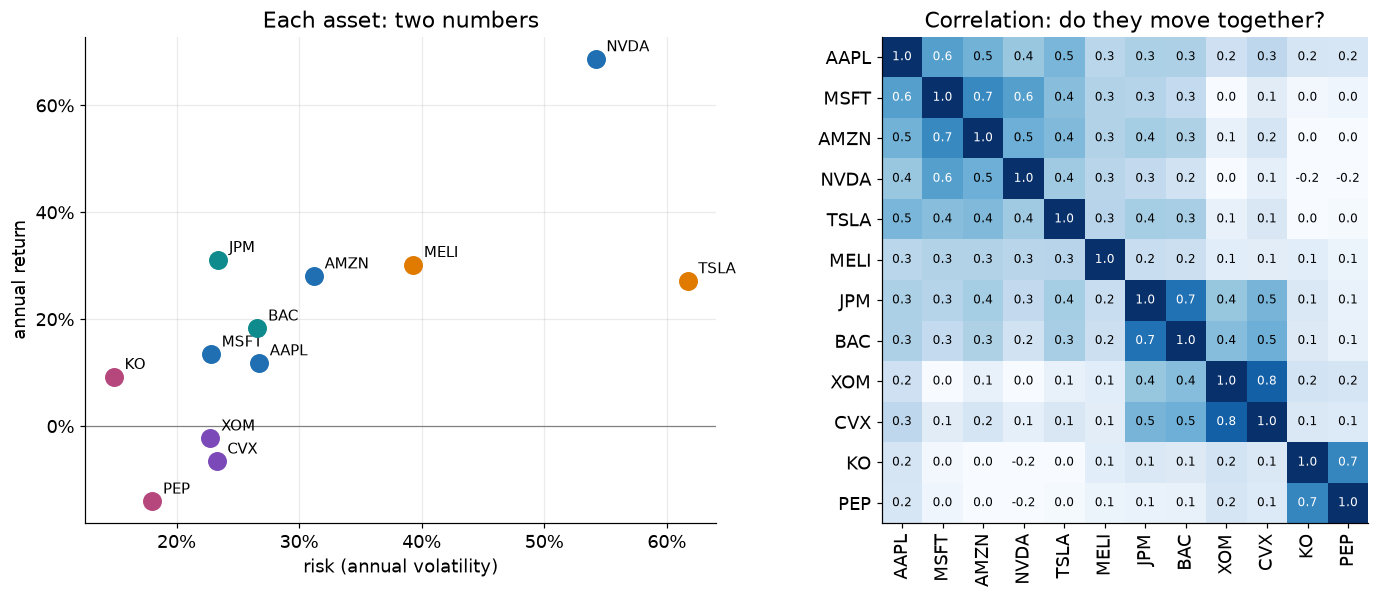

In [7]:
corr = hist_returns.corr()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={"width_ratios": [1, 1.05]})

for t in TICKERS:
    ax1.scatter(vol[t], mu[t], s=130, color=COLOR[t], zorder=3)
    ax1.annotate(t, (vol[t], mu[t]), xytext=(7, 5), textcoords="offset points", fontsize=10)
ax1.axhline(0, color="gray", lw=0.8)
ax1.set_xlabel("risk (annual volatility)"); ax1.set_ylabel("annual return")
ax1.set_title("Each asset: two numbers")
ax1.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

im = ax2.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax2.set_xticks(range(n)); ax2.set_xticklabels(TICKERS, rotation=90); ax2.set_yticks(range(n)); ax2.set_yticklabels(TICKERS)
for i in range(n):
    for j in range(n):
        v = corr.iloc[i, j]
        ax2.text(j, i, f"{(0.0 if abs(v) < 0.05 else v):.1f}", ha="center", va="center", fontsize=8, color="white" if v > 0.55 else "black")
ax2.set_title("Correlation: do they move together?"); ax2.grid(False)
plt.tight_layout(); plt.show()

### The efficient frontier

A **portfolio** is a way of splitting the money: one weight per asset, adding up to 100%.

We try 6,000 random portfolios (the dots). Then we ask a classical optimizer, for each level of return, for **the lowest-risk portfolio possible**. That curve is the **efficient frontier**: no portfolio exists above it or to its left.

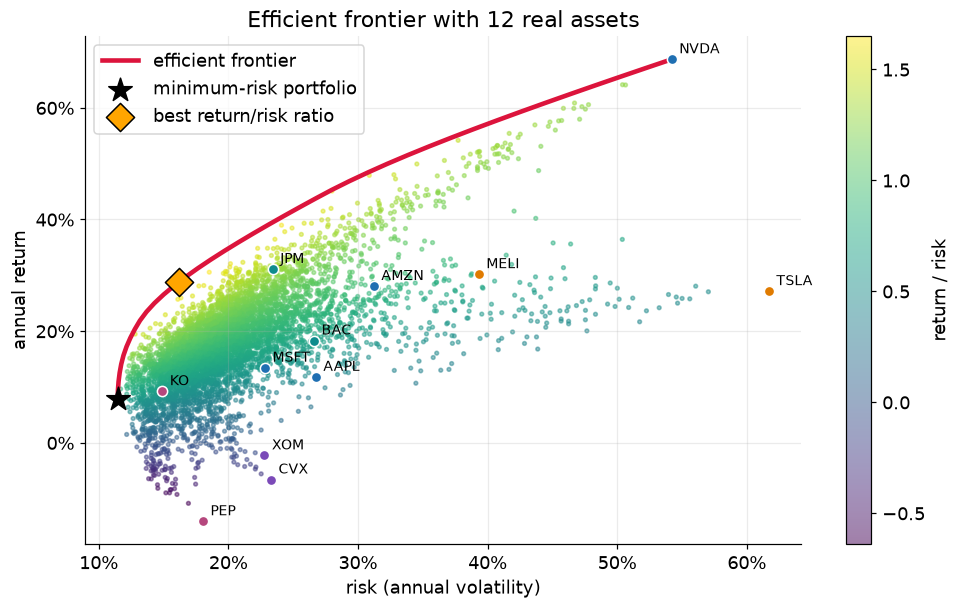

Lowest possible risk: 11.5% per year. The least risky asset on its own has 14.9%.
This is how the minimum-risk portfolio splits the money:
  KO 44%, MSFT 18%, XOM 14%, PEP 12%, JPM 5%, NVDA 2%, CVX 2%, AMZN 1%


In [8]:
m_, S_ = mu.values, cov.values
def return_and_risk(w):                   # (return, risk) of the portfolio with weights w
    return w @ m_, np.sqrt(w @ S_ @ w)

rng = np.random.default_rng(SEED)         # 6,000 random portfolios (even and concentrated)
W = np.vstack([rng.dirichlet(np.ones(n), 3000), rng.dirichlet(np.full(n, 0.2), 3000)])
rand_ret, rand_vol = W @ m_, np.sqrt(np.einsum("ij,jk,ik->i", W, S_, W))

sum_to_100 = {"type": "eq", "fun": lambda w: w.sum() - 1}    # the weights add up to 100%
between_0_and_1 = [(0, 1)] * n                               # no selling what we do not own
equal_weights = np.full(n, 1 / n)

w_min_risk = minimize(lambda w: w @ S_ @ w, equal_weights, bounds=between_0_and_1, constraints=[sum_to_100]).x
w_best_ratio = minimize(lambda w: -(w @ m_) / np.sqrt(w @ S_ @ w), equal_weights, bounds=between_0_and_1, constraints=[sum_to_100]).x

frontier = []
for target in np.linspace(return_and_risk(w_min_risk)[0], m_.max(), 40):
    sol = minimize(lambda w: w @ S_ @ w, equal_weights, bounds=between_0_and_1,
                   constraints=[sum_to_100, {"type": "eq", "fun": lambda w, o=target: w @ m_ - o}])
    if sol.success:
        frontier.append(return_and_risk(sol.x))
frontier = np.array(frontier)

fig, ax = plt.subplots(figsize=(10.5, 6))
dots = ax.scatter(rand_vol, rand_ret, c=rand_ret / rand_vol, cmap="viridis", s=6, alpha=0.5)
ax.plot(frontier[:, 1], frontier[:, 0], color="crimson", lw=3, label="efficient frontier")
r1, v1 = return_and_risk(w_min_risk); r2, v2 = return_and_risk(w_best_ratio)
ax.scatter(v1, r1, s=260, marker="*", color="black", zorder=5, label="minimum-risk portfolio")
ax.scatter(v2, r2, s=170, marker="D", color="orange", edgecolor="black", zorder=5, label="best return/risk ratio")
for t in TICKERS:
    ax.scatter(vol[t], mu[t], s=45, color=COLOR[t], edgecolor="white", zorder=4)
    ax.annotate(t, (vol[t], mu[t]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set_xlabel("risk (annual volatility)"); ax.set_ylabel("annual return"); ax.set_title("Efficient frontier with 12 real assets")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.colorbar(dots, label="return / risk"); ax.legend(loc="upper left"); plt.show()

print(f"Lowest possible risk: {v1:.1%} per year. The least risky asset on its own has {vol.min():.1%}.")
print("This is how the minimum-risk portfolio splits the money:")
print("  " + ", ".join(f"{t} {p:.0%}" for t, p in sorted(zip(TICKERS, w_min_risk), key=lambda item: -item[1]) if p > 0.005))

**What we take away from Markowitz**

- Choosing a portfolio is an **optimization problem**: the lowest risk for a given return.
- Diversifying works: the minimum-risk portfolio is less risky than the best individual asset.
- With 12 assets and continuous weights, a classical computer solves it in milliseconds.

The problem gets hard when the decisions are **yes or no**: which assets go in? With $n$ assets there are $2^n$ possible selections. With 12 that is 4,096; with 110, more than $10^{33}$. That is where heuristics, classical and quantum, are explored.

## 3. Parametric circuits: a knob that changes probabilities

A **parametric circuit** is a quantum circuit with **knobs**: rotation gates whose angle we can choose.

The simplest knob is the $R_Y(\theta)$ gate applied to a qubit that starts in $|0\rangle$:

$$R_Y(\theta)\,|0\rangle = \cos\tfrac{\theta}{2}\,|0\rangle + \sin\tfrac{\theta}{2}\,|1\rangle \qquad\Rightarrow\qquad P(\text{measure }1) = \sin^2\tfrac{\theta}{2}$$

With $\theta = 0$ we always measure 0. With $\theta = \pi$ we always measure 1. In between, a coin loaded to taste.

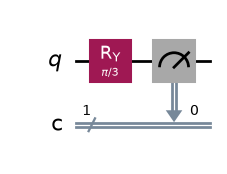

With theta = pi/3 we measure 1 in 25.3% of the cases. The formula says 25.0%


In [9]:
def simulate(circuit, shots=SHOTS):
    """Ideal simulator (no noise): repeats the circuit 'shots' times and counts what came out."""
    result = StatevectorSampler(seed=SEED).run([circuit], shots=shots).result()
    return result[0].join_data().get_counts()

def frequency_of_ones(counts, n_qubits):
    """For each qubit: in what fraction of the measurements it gave 1."""
    total = sum(counts.values())
    p1 = np.zeros(n_qubits)
    for bitstring, times in counts.items():
        for q, bit in enumerate(reversed(bitstring)):      # Qiskit writes qubit 0 on the right
            if bit == "1":
                p1[q] += times / total
    return p1

def draw(circuit, **options):
    """Draws the circuit. If the graphics library (pylatexenc) is missing, shows it as text."""
    try:
        display(circuit.draw("mpl", **options))
    except Exception:
        print(circuit.draw("text", fold=130))

knob = QuantumCircuit(1, 1)
knob.ry(np.pi / 3, 0)                # the knob: try other angles
knob.measure(0, 0)
draw(knob, scale=0.9)
print("With theta = pi/3 we measure 1 in", f"{frequency_of_ones(simulate(knob), 1)[0]:.1%}", "of the cases. The formula says", f"{np.sin(np.pi / 6) ** 2:.1%}")

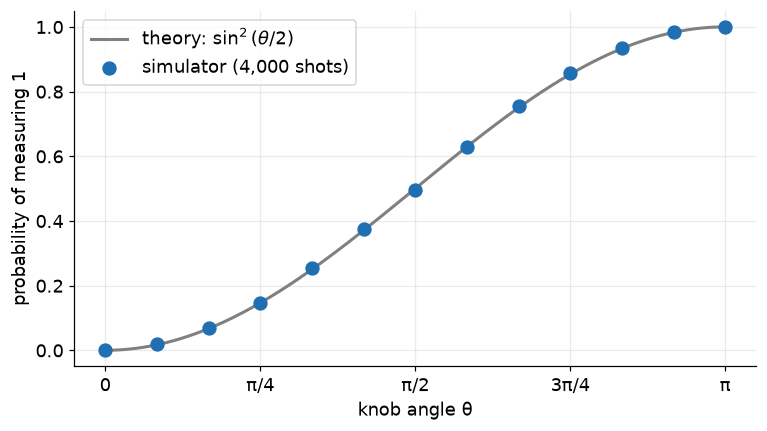

In [10]:
# We turn the knob from 0 to pi and measure 4,000 times at each position
angles = np.linspace(0, np.pi, 13)
measured = []
for theta in angles:
    qc = QuantumCircuit(1, 1); qc.ry(theta, 0); qc.measure(0, 0)
    measured.append(frequency_of_ones(simulate(qc), 1)[0])

fine = np.linspace(0, np.pi, 200)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(fine, np.sin(fine / 2) ** 2, color="gray", lw=2, label=r"theory: $\sin^2(\theta/2)$")
ax.scatter(angles, measured, s=70, color="#1f6fb2", zorder=3, label="simulator (4,000 shots)")
ax.set_xticks([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi]); ax.set_xticklabels(["0", "π/4", "π/2", "3π/4", "π"])
ax.set_xlabel("knob angle θ"); ax.set_ylabel("probability of measuring 1"); ax.legend(); plt.show()

### Loading a number into a qubit

Turning the formula around: if we want the qubit to give 1 with probability $p$, we choose

$$\theta = 2\arcsin\sqrt{p}$$

That is how a piece of **data is encoded** (for example, a risk between 0 and 1) in a qubit.

In [11]:
def angle(p):
    """Angle of the RY knob that leaves P(measure 1) = p."""
    return 2 * np.arcsin(np.sqrt(p))

for p in (0.10, 0.30, 0.75):
    qc = QuantumCircuit(1, 1); qc.ry(angle(p), 0); qc.measure(0, 0)
    print(f"we want p = {p:.2f}  ->  theta = {angle(p):.3f} rad  ->  the simulator measured 1 {frequency_of_ones(simulate(qc), 1)[0]:.1%} of the time")

we want p = 0.10  ->  theta = 0.644 rad  ->  the simulator measured 1 10.0% of the time
we want p = 0.30  ->  theta = 1.159 rad  ->  the simulator measured 1 30.1% of the time
we want p = 0.75  ->  theta = 2.094 rad  ->  the simulator measured 1 75.5% of the time


### A conditional knob: the CRY gate

The $CR_Y(\theta)$ gate connects **two** qubits: it rotates the second one **only if the first is in** $|1\rangle$.

We will use it to couple correlated assets. We read it as contagion, *"if asset A is in trouble, B's risk goes up"*, although that is an interpretation: correlation is not causation.

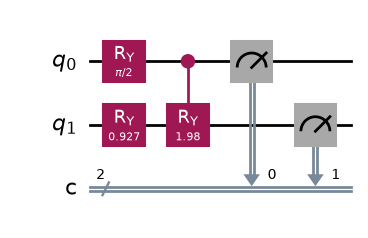

Without CRY: A = 49.1%   B = 20.5%
With CRY:    A = 49.8%   B = 58.9%   <- B went up: it caught A's risk


In [12]:
def pair(risk_a, risk_b, correlation=None):
    qc = QuantumCircuit(2, 2)
    qc.ry(angle(risk_a), 0)                        # qubit 0 = asset A
    qc.ry(angle(risk_b), 1)                        # qubit 1 = asset B
    if correlation is not None:
        qc.cry(angle(correlation), 0, 1)           # if A is in |1>, B rotates by an extra angle
    qc.measure([0, 1], [0, 1])
    return qc

draw(pair(0.5, 0.2, 0.7), scale=0.9)
alone = frequency_of_ones(simulate(pair(0.5, 0.2)), 2)
together = frequency_of_ones(simulate(pair(0.5, 0.2, 0.7)), 2)
print(f"Without CRY: A = {alone[0]:.1%}   B = {alone[1]:.1%}")
print(f"With CRY:    A = {together[0]:.1%}   B = {together[1]:.1%}   <- B went up: it caught A's risk")

## 4. The best-known path: a variational optimizer (VQE)

The two best-known quantum optimizers are:

- **VQE** (*Variational Quantum Eigensolver*, 2014)
- **QAOA** (*Quantum Approximate Optimization Algorithm*, 2014)

From the outside both work the same way: a **parametric circuit** proposes solutions and a **classical optimizer** keeps moving the knobs until the result improves. It is a loop between the quantum computer and the classical one.

**The problem.** Out of 6 assets we want to pick exactly 3. Each qubit is an asset: 1 = in, 0 = out. For each selection we compute a **cost** (lower is better):

$$\text{cost} = \text{aversion} \times \text{risk} \;-\; \text{return} \;+\; \text{penalty if they are not exactly 3}$$

With 6 assets there are $2^6 = 64$ selections: we can check them all by hand (brute force) to know the right answer.

In [13]:
MINI     = ["MSFT", "NVDA", "MELI", "JPM", "XOM", "KO"]    # 6 assets -> 6 qubits -> 64 possible portfolios
K        = 3        # how many we want to pick
AVERSION = 5        # how much risk weighs against return
PENALTY  = 1        # punishment for not picking exactly K

mu_m, cov_m, m = mu[MINI].values, cov.loc[MINI, MINI].values, len(MINI)

def cost(x):
    """Cost of a selection x (list of 0s and 1s). Each chosen asset gets 1/K of the money."""
    w = np.array(x) / K
    return AVERSION * (w @ cov_m @ w) - w @ mu_m + PENALTY * (sum(x) - K) ** 2

selections = [[(i >> q) & 1 for q in range(m)] for i in range(2 ** m)]       # the 64 combinations of 0s and 1s
costs = np.array([cost(x) for x in selections])
ranking = np.argsort(costs)                                                   # from best to worst
def name(i):
    return "+".join(t for t, bit in zip(MINI, selections[i]) if bit) or "(none)"

print("Brute force: the best 3 of the 64 portfolios")
for rank, i in enumerate(ranking[:3], 1):
    print(f"  {rank}. {name(i):15s} cost = {costs[i]:+.3f}")

Brute force: the best 3 of the 64 portfolios
  1. NVDA+JPM+KO     cost = -0.133
  2. MSFT+JPM+KO     cost = -0.083
  3. MELI+JPM+KO     cost = -0.070


**The parametric circuit** (in the jargon, the *ansatz*): a row of $R_Y$ knobs, a chain of CNOT gates that entangles the qubits, and another row of knobs. That is 12 knobs in total.

Measuring it yields a portfolio (a 6-bit string). Depending on how the knobs are set, some portfolios come out more often than others.

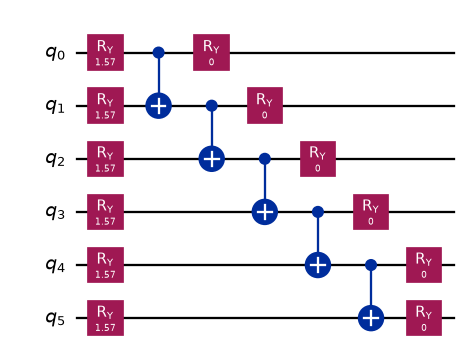

In [14]:
def ansatz(angles):
    """Parametric circuit with 6 qubits and 12 knobs."""
    qc = QuantumCircuit(m)
    for q in range(m):
        qc.ry(angles[q], q)              # first row of knobs
    for q in range(m - 1):
        qc.cx(q, q + 1)                  # entanglement
    for q in range(m):
        qc.ry(angles[m + q], q)          # second row of knobs
    return qc

start = np.concatenate([np.full(m, np.pi / 2), np.zeros(m)])     # starting point: all 64 portfolios equally likely
draw(ansatz(np.round(start, 2)), scale=0.75)

**The loop.** On each pass:

1. the circuit tells us with what probability each portfolio comes out;
2. we compute the **average cost** of what would come out when measuring;
3. the classical optimizer (COBYLA, from SciPy) moves the knobs a little to lower that cost.

On a real computer step 1 is estimated by measuring thousands of times. Here the simulator gives us the exact probabilities.

The circuit was run 400 times.
VQE chose: NVDA+JPM+KO  (it comes out 100% of the time)
   as a bitstring, in the order MSFT NVDA MELI JPM XOM KO: 010101   (1 = in, 0 = out)
Brute force says the best one is: NVDA+JPM+KO
-> The VQE portfolio is number 1 of 64.


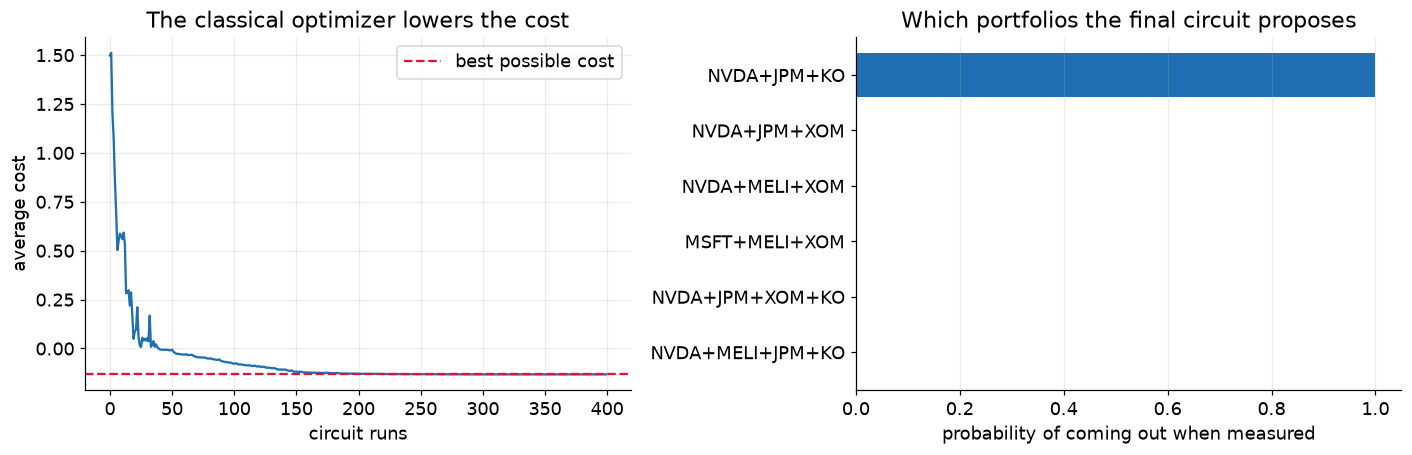

In [15]:
history = []
def average_cost(angles):
    probabilities = Statevector(ansatz(angles)).probabilities()       # one for each of the 64 portfolios
    value = float(probabilities @ costs)
    history.append(value)
    return value

optimum = minimize(average_cost, start, method="COBYLA", options={"maxiter": 400, "rhobeg": 0.6})

final_prob = Statevector(ansatz(optimum.x)).probabilities()
chosen = int(np.argmax(final_prob))
rank = int(np.where(ranking == chosen)[0][0]) + 1
print(f"The circuit was run {len(history)} times.")
print(f"VQE chose: {name(chosen)}  (it comes out {final_prob[chosen]:.0%} of the time)")
bitstring = "".join(str(b) for b in selections[chosen])
print(f"   as a bitstring, in the order {' '.join(MINI)}: {bitstring}   (1 = in, 0 = out)")
print(f"Brute force says the best one is: {name(ranking[0])}")
print(f"-> The VQE portfolio is number {rank} of 64.")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.plot(history, color="#1f6fb2"); ax1.axhline(costs.min(), color="crimson", ls="--", label="best possible cost")
ax1.set_xlabel("circuit runs"); ax1.set_ylabel("average cost"); ax1.set_title("The classical optimizer lowers the cost"); ax1.legend()
top = np.argsort(-final_prob)[:6]
ax2.barh([name(i) for i in top][::-1], final_prob[top][::-1], color="#1f6fb2")
ax2.set_xlabel("probability of coming out when measured"); ax2.set_title("Which portfolios the final circuit proposes"); ax2.grid(axis="y", alpha=0)
plt.tight_layout(); plt.show()

**What if we start somewhere else?** The result depends on the starting point. We try 10 starts with the knobs set at random:

In [16]:
hits, runs = 0, 0
for seed in range(10):
    start_angles = np.random.default_rng(seed).uniform(0, np.pi, 2 * m)
    count = []
    def f(angles):
        count.append(1)
        return float(Statevector(ansatz(angles)).probabilities() @ costs)
    sol = minimize(f, start_angles, method="COBYLA", options={"maxiter": 400, "rhobeg": 0.6})
    final = int(np.argmax(Statevector(ansatz(sol.x)).probabilities()))
    hits += int(final == ranking[0]); runs += len(count)
    print(f"  start {seed}: {name(final):15s} (rank {int(np.where(ranking == final)[0][0]) + 1} of 64)")
print(f"\nIt found the best portfolio in {hits} of 10 starts, using {runs} circuit runs in total.")

  start 0: MELI+XOM+KO     (rank 16 of 64)


  start 1: NVDA+JPM+KO     (rank 1 of 64)


  start 2: MELI+XOM+KO     (rank 16 of 64)


  start 3: JPM+XOM+KO      (rank 11 of 64)


  start 4: NVDA+JPM+KO     (rank 1 of 64)


  start 5: MELI+JPM+KO     (rank 3 of 64)


  start 6: NVDA+XOM+KO     (rank 4 of 64)


  start 7: MSFT+MELI+JPM   (rank 8 of 64)


  start 8: MSFT+JPM+KO     (rank 2 of 64)


  start 9: NVDA+XOM+KO     (rank 4 of 64)

It found the best portfolio in 2 of 10 starts, using 3853 circuit runs in total.


### VQE with all 12 assets: the same problem as our circuit

To compare like with like against the circuit in section 5, we give VQE **the same problem**: the 12 assets, pick exactly 6, and a cost that looks at **risk only**, the variance of the portfolio with the 6 in equal parts. That is 12 qubits, 4,096 states that the simulator computes exactly, and 24 knobs. Since the result depends on the start, we try 10 and keep the one with the lowest cost, a decision made inside HISTORY. Brute force over the 924 selections tells us the right answer.

In [17]:
K12 = 6
sel12 = np.array([[(i >> q) & 1 for q in range(n)] for i in range(2 ** n)], float)      # the 4,096 selections of 0s and 1s
W12 = sel12 / K12
costs12 = np.einsum("ij,jk,ik->i", W12, S_, W12) + PENALTY * (sel12.sum(1) - K12) ** 2  # risk only, plus the penalty
ranking12 = np.argsort(costs12)
name12 = lambda i: "+".join(t for t, bit in zip(TICKERS, sel12[i]) if bit)

def ansatz12(angles, layers=2):
    qc = QuantumCircuit(n)
    for c in range(layers):
        for q in range(n):
            qc.ry(angles[c * n + q], q)
        if c < layers - 1:
            for q in range(n - 1):
                qc.cx(q, q + 1)
    return qc

def average_cost12(angles):
    return float(Statevector(ansatz12(angles)).probabilities() @ costs12)

print(f"Brute force, the best of the 924 selections of 6: {name12(ranking12[0])}")
results12 = []
for seed in range(10):
    start_angles = np.random.default_rng(SEED + seed).uniform(0, np.pi, 2 * n)
    sol = minimize(average_cost12, start_angles, method="COBYLA", options={"maxiter": 600, "rhobeg": 0.6})
    final = int(np.argmax(Statevector(ansatz12(sol.x)).probabilities()))
    results12.append((float(costs12[final]), final, sol.nfev))
    print(f"  start {seed}: {name12(final):38s} rank {int(np.where(ranking12 == final)[0][0]) + 1:4d} of 4096")
cost_vqe12, chosen12, _ = min(results12)
sel_vqe12 = [t for t, bit in zip(TICKERS, sel12[chosen12]) if bit]
print(f"\nVQE keeps the start with the lowest cost: {name12(chosen12)}, rank {int(np.where(ranking12 == chosen12)[0][0]) + 1} of 4096, "
      f"with {sum(r[2] for r in results12)} circuit runs in total.")

Brute force, the best of the 924 selections of 6: MSFT+JPM+XOM+CVX+KO+PEP


  start 0: MSFT+NVDA+TSLA+BAC+XOM+KO              rank  661 of 4096


  start 1: AMZN+NVDA+JPM+BAC+CVX+PEP              rank  373 of 4096


  start 2: AAPL+AMZN+TSLA+JPM+XOM+CVX             rank  668 of 4096


  start 3: MSFT+MELI+JPM+BAC+KO+PEP               rank   55 of 4096


  start 4: AAPL+AMZN+TSLA+JPM+BAC+KO              rank  654 of 4096


  start 5: AMZN+NVDA+TSLA+JPM+CVX+KO              rank  764 of 4096


  start 6: AAPL+MSFT+NVDA+JPM+XOM+KO              rank  241 of 4096


  start 7: AMZN+JPM+BAC+XOM+KO+PEP                rank   29 of 4096


  start 8: MSFT+AMZN+MELI+JPM+XOM+KO              rank  126 of 4096


  start 9: AAPL+NVDA+MELI+BAC+CVX+PEP             rank  396 of 4096

VQE keeps the start with the lowest cost: AMZN+JPM+BAC+XOM+KO+PEP, rank 29 of 4096, with 6000 circuit runs in total.


**What we take away from VQE and QAOA**

- They are **hybrid**: a quantum circuit proposes and a classical optimizer corrects, in a loop.
- They need **hundreds of runs** of the circuit. On real hardware, each one is a job in the queue.
- They are **heuristics**: they do not guarantee the best solution and can get stuck in a mediocre one.
- **QAOA** uses the same loop with a more structured circuit: it starts with a **Hadamard gate on every qubit** (all portfolios at once) and alternates "cost" and "mixing" layers. It has only 2 knobs per layer.
- To this day, on portfolios with real data, classical methods keep winning.

## 5. Our approach: a circuit that estimates the risk of each asset

We change the question. Instead of asking the circuit to **search** for the best portfolio, we use it to **estimate a risk index** for each asset, and with that we build a low-risk portfolio.

- **One qubit per asset.**
- One $R_Y$ knob per asset loads its **own risk**.
- $CR_Y$ gates between highly correlated assets couple their qubits: we read it as **contagion**.
- We measure: the frequency with which each qubit gives 1 is that asset's **risk index**.

The key point: **there is no optimization loop**. The angles are computed once, straight from the historical data.

### 5.1 Each asset's own risk

A **bad day** is a day when the asset falls by more than one standard deviation of its own returns. We look at two things:

- **frequency**: how often it has bad days;
- **average drop**: how much it loses on those days.

We bring each one to the 0-to-1 scale within the group, multiply them and rescale. The result is $R$: 0 for the calmest in the group, 1 for the riskiest. It is an index relative to the group and to the time window, not an absolute risk: $R = 0.8$ does not mean "80% risk".

In [18]:
def own_risk(returns):
    rows = {}
    for t in returns.columns:
        r = returns[t]
        bad_day = r < -r.std()                                    # fell by more than 1 standard deviation
        rows[t] = {"frequency": bad_day.mean(), "average_drop": -r[bad_day].mean()}
    table = pd.DataFrame(rows).T
    to_scale = lambda v: (v - v.min()) / (v.max() - v.min())      # brings the values to the 0-to-1 range
    table["R"] = to_scale(to_scale(table["frequency"]) * to_scale(table["average_drop"]))
    return table

risk_table = own_risk(hist_returns)
R = risk_table["R"].values
risk_table.sort_values("R").style.format({"frequency": "{:.1%}", "average_drop": "{:.2%}", "R": "{:.3f}"}).bar(subset=["R"], color="#f2c38b", vmin=0, vmax=1)

,frequency,average_drop,R
JPM,7.0%,3.08%,0.000
KO,10.6%,1.56%,0.000
BAC,8.6%,3.01%,0.128
PEP,12.4%,2.04%,0.142
MSFT,11.4%,2.54%,0.236
AAPL,10.6%,3.03%,0.292
XOM,14.1%,2.36%,0.314
CVX,12.2%,2.70%,0.325
AMZN,10.6%,3.37%,0.359
MELI,11.4%,3.97%,0.585


### 5.2 The contagion map

For each asset we look for its (up to) 3 most correlated neighbors, and we only connect them if the correlation is 0.6 or more. Each connection $i \to j$ reads: *"if $i$ is in trouble, it pushes $j$"*. It is a heuristic reading of correlation, which does not imply causation.

8 connections: MSFT→AMZN (0.66), AMZN→MSFT (0.66), JPM→BAC (0.75), BAC→JPM (0.75), XOM→CVX (0.82), CVX→XOM (0.82), KO→PEP (0.67), PEP→KO (0.67)


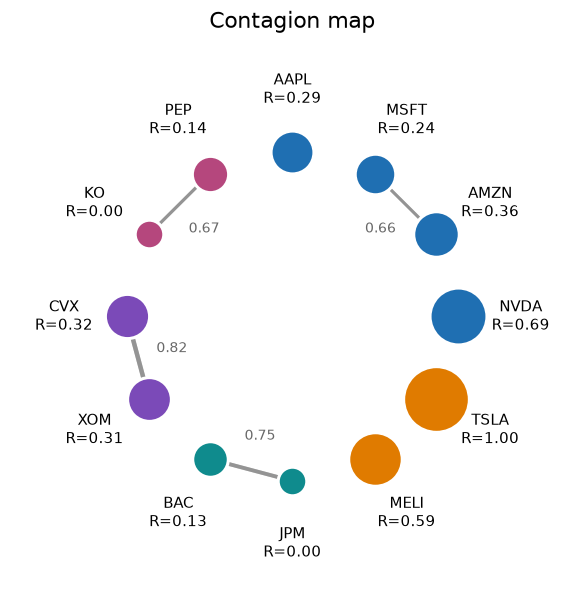

In [19]:
def contagion_map(corr, neighbors=3, threshold=0.6):
    """List of connections (i, j, correlation): asset i spreads to asset j.
    Only positive correlations at or above the threshold count: a negative correlation is not contagion."""
    c = corr.values
    strength = c.copy(); np.fill_diagonal(strength, 0)
    connections = []
    for i in range(len(c)):
        for j in np.argsort(-strength[i])[:neighbors]:
            if strength[i, j] >= threshold:
                connections.append((i, int(j), float(c[i, j])))
    return connections

connections = contagion_map(corr)
print(f"{len(connections)} connections:", ", ".join(f"{TICKERS[i]}→{TICKERS[j]} ({c:.2f})" for i, j, c in connections))

# Drawing: each asset is a circle (bigger = more own risk); the lines are the connections
ang = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, n, endpoint=False)
pos = np.c_[np.cos(ang), np.sin(ang)]
fig, ax = plt.subplots(figsize=(6.6, 6.6))
for i, j, c in connections:
    ax.plot(*zip(pos[i], pos[j]), color="gray", lw=1 + 6 * (abs(c) - 0.5), alpha=0.6, zorder=1)
    if i < j:                                             # the correlation, written only once per pair
        ax.annotate(f"{c:.2f}", (pos[i] + pos[j]) / 2 * 0.78, ha="center", va="center", fontsize=9, color="dimgray")
for k, t in enumerate(TICKERS):
    ax.scatter(*pos[k], s=350 + 1500 * R[k], color=COLOR[t], edgecolor="white", lw=2, zorder=2)
    ax.annotate(f"{t}\nR={R[k]:.2f}", pos[k] * 1.38, ha="center", va="center", fontsize=10)
ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.7, 1.7); ax.axis("off"); ax.set_title("Contagion map"); plt.show()

### 5.3 The circuit

Two layers, in this order:

1. **Own risk:** $R_Y(\theta_j)$ with $\theta_j = 2\arcsin\sqrt{R_j}$, so that $P(1) = R_j$.
2. **Contagion:** one $CR_Y$ per connection, with angle $2\arcsin\sqrt{\text{correlation}}$ (only positive correlations go in).

One detail: we clip $R$ at 0.95 so that the riskiest asset does not get stuck in $|1\rangle$.

12 qubits, 8 CRY gates, depth 4


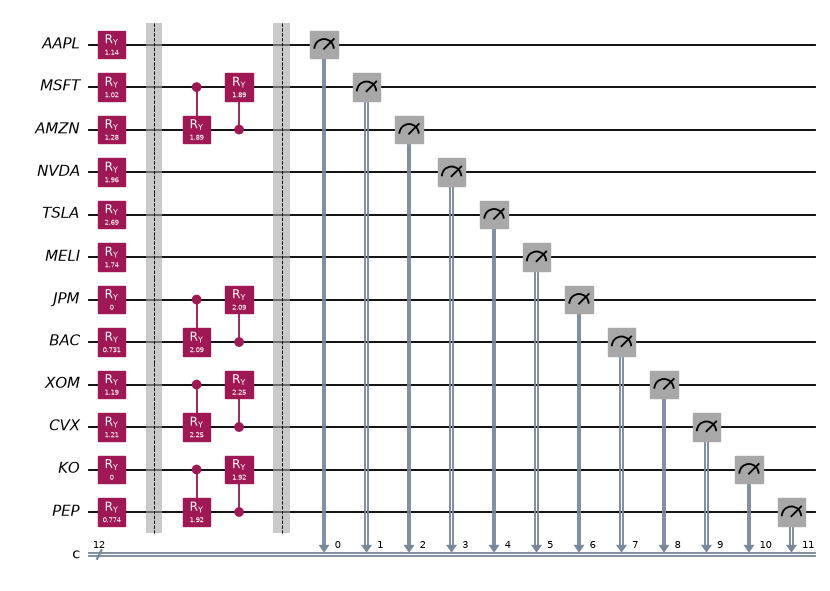

In [20]:
R_circuit = np.minimum(R, 0.95)

def risk_circuit(R, connections, hadamard=False, measure=True, names=TICKERS):
    n_q = len(R)
    qc = QuantumCircuit(*[QuantumRegister(1, t) for t in names])      # one qubit per asset, with its name
    if measure:
        qc.add_register(ClassicalRegister(n_q, "c"))
    if hadamard:                                   # only for the experiment in section 6
        qc.h(range(n_q))
    for j in range(n_q):                           # 1) own risk
        qc.ry(angle(R[j]), j)
    qc.barrier()
    for i, j, c in connections:                    # 2) contagion between correlated assets
        qc.cry(angle(min(c, 0.95)), i, j)
    if measure:
        qc.barrier()
        qc.measure(range(n_q), range(n_q))
    return qc

qc_risk = risk_circuit(R_circuit, connections)
print(f"{qc_risk.num_qubits} qubits, {len(connections)} CRY gates, depth {qc_risk.depth()}")
draw(qc_risk, fold=-1, scale=0.6)

### 5.4 Simulation

With 12 qubits the simulator can compute the **exact** result. We also run it as in real life: repeating 4,000 times and counting.

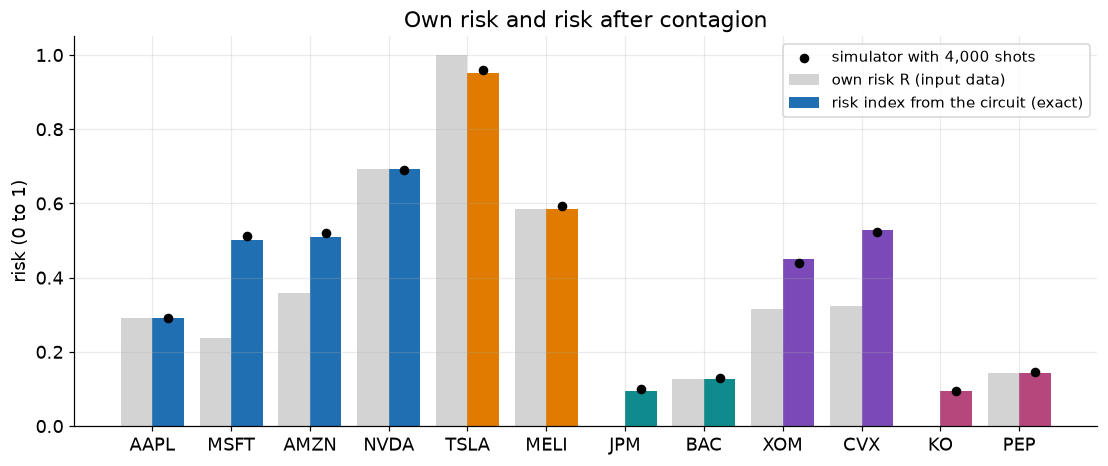

Go up through contagion:    MSFT (+0.27), AMZN (+0.15), JPM (+0.10), XOM (+0.13), CVX (+0.20), KO (+0.10)
Connected but unchanged:    BAC, PEP
No connections:             AAPL, NVDA, TSLA, MELI


In [21]:
def exact_index(circuit_without_measurement):
    """Exact probability that each qubit gives 1 (no noise and no sampling error)."""
    state = Statevector(circuit_without_measurement)
    return np.array([state.probabilities([q])[1] for q in range(circuit_without_measurement.num_qubits)])

ideal_index = exact_index(risk_circuit(R_circuit, connections, measure=False))
sim_index = frequency_of_ones(simulate(qc_risk), n)

x = np.arange(n)
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.bar(x - 0.2, R, 0.4, color="lightgray", label="own risk R (input data)")
ax.bar(x + 0.2, ideal_index, 0.4, color=[COLOR[t] for t in TICKERS], label="risk index from the circuit (exact)")
ax.scatter(x + 0.2, sim_index, color="black", s=28, zorder=3, label="simulator with 4,000 shots")
ax.set_xticks(x); ax.set_xticklabels(TICKERS); ax.set_ylabel("risk (0 to 1)"); ax.legend(loc="upper right", fontsize=10)
ax.set_title("Own risk and risk after contagion"); plt.show()

change = ideal_index - R_circuit
receivers = {j for _, j, _ in connections}                 # assets that receive some connection
print("Go up through contagion:   ", ", ".join(f"{t} (+{change[k]:.2f})" for k, t in enumerate(TICKERS) if change[k] > 0.005))
print("Connected but unchanged:   ", ", ".join(t for k, t in enumerate(TICKERS) if k in receivers and abs(change[k]) <= 0.005))
print("No connections:            ", ", ".join(t for k, t in enumerate(TICKERS) if k not in receivers))

**How to read it.**

- Assets with **no connections** come out with their own risk, exactly as it went in.
- Those with a highly correlated partner **go up**: a calm asset, tied to a riskier one, is no longer so calm.
- The $CR_Y$ does not add risks: in the branch where the control is 1, the target ends up rotated by $\theta_j + \theta_{ij}$ and its probability is $\sin^2\big((\theta_j+\theta_{ij})/2\big)$, which grows as long as the sum does not exceed $\pi$. With these data it always grows.
- A connected asset may **not change** if the one that spreads to it has own risk 0: that qubit never "switches on". With these data it happens with BAC and PEP, whose partners (JPM and KO) are the calmest in the group.

### 5.5 Is the quantum part needed? A classical reference model

To be honest, we build the same idea **without** a quantum computer: risk diffuses through the same contagion map (similar to how PageRank spreads importance among web pages). If the circuit contributes nothing different, the two orderings will match.

In [22]:
def classical_diffusion(R, connections, alpha=0.5, steps=3):
    """Each asset mixes its own risk with that of the neighbors that spread to it."""
    n_a = len(R)
    W = np.zeros((n_a, n_a))
    for i, j, c in connections:
        W[i, j] = abs(c)
    row_sums = W.sum(axis=1, keepdims=True); row_sums[row_sums == 0] = 1
    T = W / row_sums
    score = R.copy()
    for _ in range(steps):
        score = (1 - alpha) * R + alpha * (T.T @ score)
    return score

classical_index = classical_diffusion(R, connections)
comparison = pd.DataFrame({"own risk R": R, "circuit (ideal)": ideal_index, "classical (diffusion)": classical_index}, index=TICKERS)
print(f"Agreement between the circuit's ordering and the classical model's (Spearman, 1 = identical): {spearmanr(ideal_index, classical_index).statistic:.2f}")
comparison.sort_values("circuit (ideal)").style.format("{:.3f}").background_gradient(cmap="Oranges", vmin=0, vmax=1)

Agreement between the circuit's ordering and the classical model's (Spearman, 1 = identical): 0.92


,own risk R,circuit (ideal),classical (diffusion)
KO,0.000,0.095,0.053
JPM,0.000,0.096,0.048
BAC,0.128,0.128,0.080
PEP,0.142,0.142,0.089
AAPL,0.292,0.292,0.146
XOM,0.314,0.449,0.318
MSFT,0.236,0.502,0.282
AMZN,0.359,0.510,0.313
CVX,0.325,0.529,0.321
MELI,0.585,0.585,0.293


### 5.6 From risk index to portfolio

A rule with no cutoff: **each of the 12 assets enters the portfolio with a weight inversely proportional to its risk index**. The calmest weighs the most; the riskiest weighs little, but it is in. There is no number of assets chosen by us, no cap, no optimizer: the portfolio is, end to end, the result of the circuit.

It is the most honest rule for evaluating the method, because the only thing that can go right or wrong is the ordering the circuit gave. The exact classical analogue, weighting by 1 / historical volatility, appears as a control in section 8.

In [23]:
def portfolio_from_risk_index(index, eps=1e-3):
    """Each asset gets a weight inversely proportional to its risk index. All 12 go in, with no cutoff."""
    weights = 1 / (np.asarray(index, float) + eps)
    return weights / weights.sum()

w_quantum = portfolio_from_risk_index(ideal_index)
w_classical = portfolio_from_risk_index(classical_index)
print("Portfolio with the circuit's index:", ", ".join(f"{t} {p:.0%}" for t, p in sorted(zip(TICKERS, w_quantum), key=lambda item: -item[1])))
print("Portfolio with the classical index:", ", ".join(f"{t} {p:.0%}" for t, p in sorted(zip(TICKERS, w_classical), key=lambda item: -item[1])))

Portfolio with the circuit's index: KO 20%, JPM 20%, BAC 15%, PEP 14%, AAPL 7%, XOM 4%, MSFT 4%, AMZN 4%, CVX 4%, MELI 3%, NVDA 3%, TSLA 2%
Portfolio with the classical index: JPM 23%, KO 20%, BAC 14%, PEP 12%, AAPL 8%, MSFT 4%, MELI 4%, AMZN 4%, XOM 3%, CVX 3%, NVDA 3%, TSLA 2%


## 6. Why don't we start with Hadamard?

Many quantum algorithms begin with a **Hadamard gate on every qubit**: it leaves each qubit half 0 and half 1, so the circuit "sees" all combinations at once. That is what QAOA does.

Our first version also started that way. It was a mistake, and it is worth understanding.

We do not want to explore combinations: we want to **load a number** into each qubit. If we put a Hadamard before the knob, the qubit already starts at 50%, and the knob rotates from there:

$$\text{without Hadamard: } P(1) = R \qquad\qquad \text{with Hadamard: } P(1) = \tfrac12 + \sqrt{R\,(1-R)}$$

The second formula **folds**: it rises until $R = 0.5$ and then falls. Two very different risks end up with the same readout.

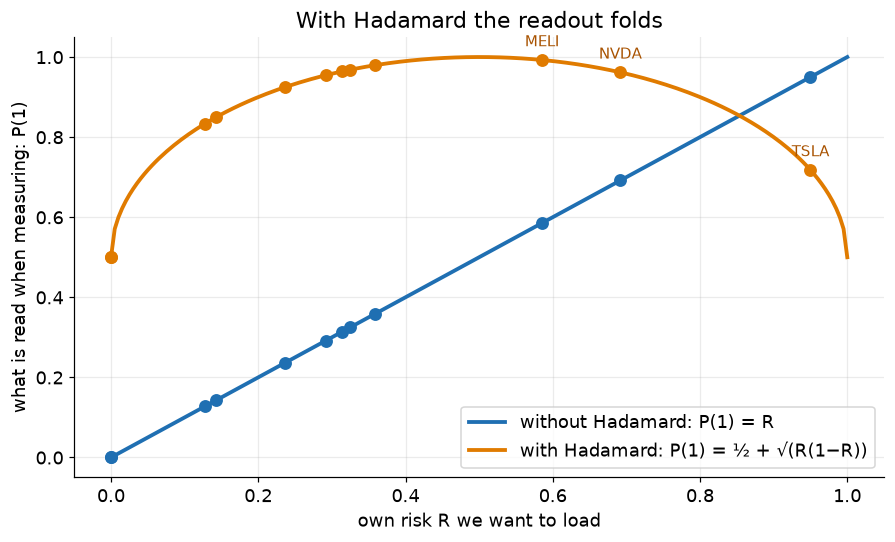

R = 0.25 and R = 0.75 with Hadamard give the same: 0.933
The riskiest one (TSLA, R = 0.95) with Hadamard reads 0.72: it looks less risky than a medium-risk one.
Is the risk ordering preserved?  without Hadamard: 1.00   with Hadamard: 0.61   (1 = perfectly preserved)


In [24]:
no_h = exact_index(risk_circuit(R_circuit, [], hadamard=False, measure=False))       # only the own-risk layer
with_h = exact_index(risk_circuit(R_circuit, [], hadamard=True,  measure=False))

r = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.plot(r, r, color="#1f6fb2", lw=2.5, label="without Hadamard: P(1) = R")
ax.plot(r, 0.5 + np.sqrt(r * (1 - r)), color="#e07b00", lw=2.5, label="with Hadamard: P(1) = ½ + √(R(1−R))")
ax.scatter(R_circuit, no_h, color="#1f6fb2", s=55, zorder=3)
ax.scatter(R_circuit, with_h, color="#e07b00", s=55, zorder=3)
for t, x_, y_ in zip(TICKERS, R_circuit, with_h):
    if x_ > 0.5:                                          # we label only the riskiest ones
        ax.annotate(t, (x_, y_), xytext=(0, 9), textcoords="offset points", fontsize=10, ha="center", color="#a85200")
ax.set_xlabel("own risk R we want to load"); ax.set_ylabel("what is read when measuring: P(1)")
ax.set_title("With Hadamard the readout folds"); ax.legend(loc="lower right"); plt.show()

print(f"R = 0.25 and R = 0.75 with Hadamard give the same: {0.5 + np.sqrt(0.25 * 0.75):.3f}")
print(f"The riskiest one ({TICKERS[int(np.argmax(R))]}, R = 0.95) with Hadamard reads {with_h[int(np.argmax(R))]:.2f}: it looks less risky than a medium-risk one.")
print(f"Is the risk ordering preserved?  without Hadamard: {spearmanr(R, no_h).statistic:.2f}   with Hadamard: {spearmanr(R, with_h).statistic:.2f}   (1 = perfectly preserved)")

**The rule we take away**

- **Hadamard** is useful when the algorithm needs to go through many combinations at once (QAOA, Grover).
- To **load a piece of data** into a qubit it is better to start in $|0\rangle$ and use only the $R_Y$ knob. The qubit still ends up in superposition, but in just the right one: the one with $P(1) = R$.

Not every qubit has to start in the even superposition. It depends on what the circuit is used for.

## 7. From the simulator to a real quantum computer

So far everything was ideal. A real quantum computer differs in two ways:

- **Noise**: gates and measurements fail a little.
- **Its own gates and connections**: the chip has no CRY gates and does not connect every qubit to every other. The circuit has to be **translated** (this is called *transpiling*).

We go in two steps: first a **dress rehearsal** on our own machine, with a simulator that imitates the noise of the real chip, and then the real chip.

### 7.1 Dress rehearsal: a simulator with the noise of `ibm_fez`

`FakeFez` is a copy of the characteristics of the **ibm_fez** processor (IBM Heron r2, 156 qubits), the same one we used in the paper. The code is identical to the one for real hardware; only the `backend` changes.

In [25]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeFez

def translate(circuit, backend):
    """Rewrites the circuit with the chip's gates and connections."""
    return generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=SEED).run(circuit)

def two_qubit_gates(circuit):
    """Number of two-qubit gates (the noisiest ones)."""
    return sum(1 for inst in circuit.data if inst.operation.num_qubits == 2)

simulated_chip = FakeFez()
qc_chip = translate(qc_risk, simulated_chip)
print(f"Original circuit  : depth {qc_risk.depth()}, {len(connections)} CRY gates")
print(f"Translated circuit: depth {qc_chip.depth()}, {two_qubit_gates(qc_chip)} two-qubit gates, using {dict(qc_chip.count_ops())}")

sampler = Sampler(mode=simulated_chip)
sampler.options.simulator.seed_simulator = SEED
noisy_counts = sampler.run([qc_chip], shots=SHOTS).result()[0].join_data().get_counts()
noisy_index = frequency_of_ones(noisy_counts, n)

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
print(f"\nRMSE against the ideal (the typical gap): {rmse(noisy_index, ideal_index):.3f}")

Original circuit  : depth 4, 8 CRY gates
Translated circuit: depth 15, 8 two-qubit gates, using {'sx': 52, 'rz': 45, 'measure': 12, 'cz': 8, 'barrier': 2}



RMSE against the ideal (the typical gap): 0.010


### 7.2 The real chip: IBM Quantum

To send the circuit to a real computer you need a free account at [IBM Quantum](https://quantum.cloud.ibm.com) and its key (*API key*). The key is **never** written in the notebook: it goes in a `.env` file (there is a template in `.env.example`) or in an account saved with `QiskitRuntimeService.save_account(...)`. The notebook looks for `.env` next to itself and then in the three folders above it, up to the repository root.

The next cell:

- if `RUN_ON_HARDWARE = True`, sends the circuit, saves the job id and waits for the result;
- if it is `False`, shows the last result saved in `data/hardware_result.json` (or fetches it, if the job has already finished).

The free plan gives 10 minutes of processor time per month. This circuit uses a few seconds, but the **queue** can be long: it is best to send it before the class.

In [26]:
RUN_ON_HARDWARE = False               # <- change to True to send the circuit to the real quantum computer
REAL_BACKEND = "ibm_fez"              # 156-qubit IBM Heron r2 (the same one as in the paper)
HW_FILE = DATA / "hardware_result.json"

def connect_ibm():
    """Connects to IBM Quantum using the .env file (IBM_API_KEY, IBM_INSTANCE) or the saved account."""
    from qiskit_ibm_runtime import QiskitRuntimeService
    for env_file in (Path(".env"), Path("../.env"), Path("../../.env"), Path("../../../.env")):
        if env_file.exists():
            for line in env_file.read_text(encoding="utf-8").splitlines():
                if "=" in line and not line.strip().startswith("#"):
                    key, value = line.split("=", 1)
                    os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))
            break
    if os.getenv("IBM_API_KEY"):
        account = {"token": os.environ["IBM_API_KEY"], "channel": os.getenv("IBM_CHANNEL") or "ibm_quantum_platform"}
        if os.getenv("IBM_INSTANCE"):
            account["instance"] = os.environ["IBM_INSTANCE"]
        return QiskitRuntimeService(**account)
    return QiskitRuntimeService()                      # account saved with save_account(...)

def save(record):
    HW_FILE.parent.mkdir(parents=True, exist_ok=True)
    HW_FILE.write_text(json.dumps(record, indent=1), encoding="utf-8")

if RUN_ON_HARDWARE:
    real_backend = connect_ibm().backend(REAL_BACKEND)
    print(f"{real_backend.name}: {real_backend.num_qubits} qubits, {real_backend.status().pending_jobs} jobs in the queue")
    qc_real = translate(qc_risk, real_backend)
    job = Sampler(mode=real_backend).run([qc_real], shots=SHOTS)
    record = {"backend": real_backend.name, "job_id": job.job_id(), "submitted": datetime.now().isoformat(timespec="seconds"),
              "assets": TICKERS, "R": [round(float(v), 6) for v in R_circuit], "shots": SHOTS,
              "depth": qc_real.depth(), "two_qubit_gates": two_qubit_gates(qc_real), "counts": None}
    save(record)                                       # we save the job id before waiting
    print("Job sent:", record["job_id"], "| waiting for the result (you can interrupt: the job stays in the queue)")
    record["counts"] = job.result()[0].join_data().get_counts()
    save(record)
    try:
        print(f"Done. Quantum processor time used: {job.usage():.0f} seconds")
    except Exception:
        pass

hw_index, record = None, None
if HW_FILE.exists():
    record = json.loads(HW_FILE.read_text(encoding="utf-8"))
    if record["counts"] is None:                       # it was sent earlier and we have not fetched the result yet
        job = connect_ibm().job(record["job_id"])
        print(f"Job {record['job_id']}: status {job.status()}")
        if job.done():
            record["counts"] = job.result()[0].join_data().get_counts()
            save(record)
    if record["counts"] is not None:
        if record["assets"] == TICKERS and np.allclose(record["R"], R_circuit, atol=0.02):
            hw_index = frequency_of_ones(record["counts"], n)
            print(f"Real hardware result: {record['backend']}, job {record['job_id']}, sent on {record['submitted']}")
            print(f"Translated circuit: depth {record['depth']}, {record['two_qubit_gates']} two-qubit gates, {record['shots']} shots")
            print(f"RMSE against the ideal (the typical gap): {rmse(hw_index, ideal_index):.3f}")
        else:
            print("There is a saved result, but it is from another circuit (the assets or the data changed). Send it again with RUN_ON_HARDWARE = True.")
else:
    print("There is no saved hardware result yet.")
    print("To get one: fill in the .env file, set RUN_ON_HARDWARE = True and run this cell.")

Real hardware result: ibm_fez, job db1djj3id5ic73er0ceg, sent on 2026-10-04T19:57:17
Translated circuit: depth 15, 8 two-qubit gates, 4000 shots
RMSE against the ideal (the typical gap): 0.015


**The bitstrings the chip measured.** Each measurement returns 12 bits, one per asset. Here a 1 does not mean "it goes into the portfolio", as in VQE, but "this qubit ended up in 1 in this measurement": each bitstring is a **synthetic scenario of the model**, a sample from the joint distribution the circuit built, not an observation of stocks falling in the market. In 4,000 shots hundreds of different scenarios come out; below, the most frequent ones. The method does not use any particular bitstring: it uses the **frequency of 1 of each qubit**, which is its risk index.

In [27]:
if record is not None and record["counts"] is not None:
    counts = record["counts"]
    print(f"{len(counts)} distinct bitstrings in {sum(counts.values())} shots. The 5 most frequent:")
    for bitstring, times in sorted(counts.items(), key=lambda kv: -kv[1])[:5]:
        bits = bitstring[::-1]                                     # Qiskit writes qubit 0 on the right
        at_one = [t for t, b in zip(TICKERS, bits) if b == "1"]
        print(f"  {bitstring}  {times:4d} times   at 1: {', '.join(at_one)}")
    print("None of these bitstrings is the portfolio: the portfolio comes from the frequency of 1 of each qubit.")

526 distinct bitstrings in 4000 shots. The 5 most frequent:
  000000111110   185 times   at 1: MSFT, AMZN, NVDA, TSLA, MELI
  000000111000   157 times   at 1: NVDA, TSLA, MELI
  001100111000   156 times   at 1: NVDA, TSLA, MELI, XOM, CVX
  001100111110   140 times   at 1: MSFT, AMZN, NVDA, TSLA, MELI, XOM, CVX
  001100011000   131 times   at 1: NVDA, TSLA, XOM, CVX
None of these bitstrings is the portfolio: the portfolio comes from the frequency of 1 of each qubit.


### 7.3 Ideal, noisy rehearsal and hardware

If everything were perfect, every point would fall on the diagonal.

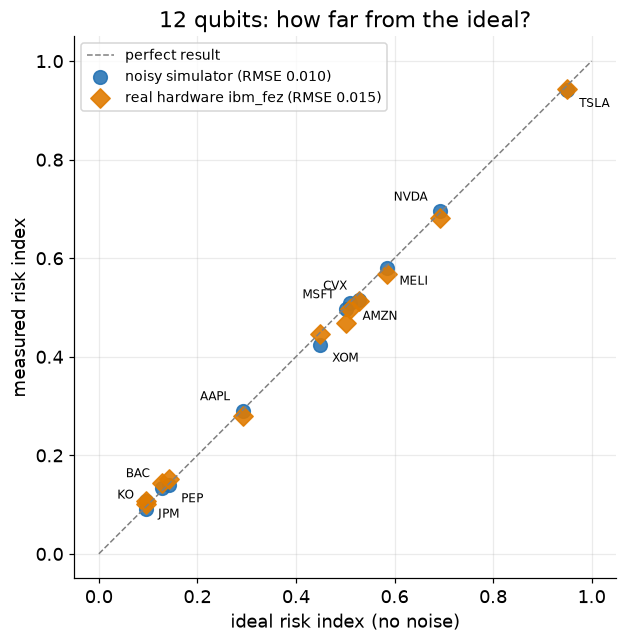

In [28]:
fig, ax = plt.subplots(figsize=(6.8, 6.4))
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="perfect result")
ax.scatter(ideal_index, noisy_index, s=80, color="#1f6fb2", alpha=0.85, label=f"noisy simulator (RMSE {rmse(noisy_index, ideal_index):.3f})")
if hw_index is not None:
    ax.scatter(ideal_index, hw_index, s=80, marker="D", color="#e07b00", alpha=0.9,
               label=f"real hardware {record['backend']} (RMSE {rmse(hw_index, ideal_index):.3f})")
for rank_, k in enumerate(np.argsort(ideal_index)):           # alternating labels so they do not overlap
    ax.annotate(TICKERS[k], (ideal_index[k], noisy_index[k]), xytext=(8, -11) if rank_ % 2 else (-8, 7),
                textcoords="offset points", fontsize=8, ha="left" if rank_ % 2 else "right")
ax.set_xlabel("ideal risk index (no noise)"); ax.set_ylabel("measured risk index")
ax.set_title("12 qubits: how far from the ideal?"); ax.legend(loc="upper left", fontsize=9); ax.set_aspect("equal"); plt.show()

### 7.4 At scale: the real 110-qubit experiment

With 12 qubits and a short circuit, noise is barely noticeable. The experiment in the paper used **110 assets = 110 qubits** on `ibm_fez`: 129 CRY gates which, translated to the chip, are 551 two-qubit gates with depth 391.

These are the real data from that run (June 27, 2026, 5 repetitions of 4,000 shots).

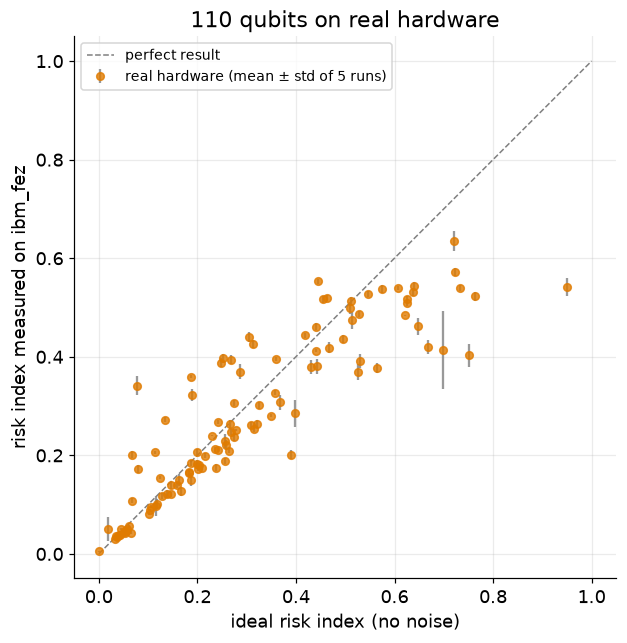

110 assets. Agreement of the ordering with the ideal (Spearman): 0.92
RMSE against the ideal (the typical gap): 0.102
The 5 with the LOWEST risk  ->  ideal: APD, UL, LMT, LIN, PG  | hardware: APD, LMT, PG, LIN, V
The 5 with the HIGHEST risk ->  ideal: SMCI, TSLA, SNOW, QCOM, SHOP  | hardware: ENPH, SHOP, TXN, TSM, SMCI


In [29]:
file_110 = DATA / "110_qubit_experiment_ibm_fez.csv"
if file_110.exists():
    exp = pd.read_csv(file_110)
    fig, ax = plt.subplots(figsize=(6.8, 6.4))
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1, label="perfect result")
    ax.errorbar(exp["q_ideal"], exp["q_hw_mean"], yerr=exp["q_hw_std"], fmt="o", ms=5, color="#e07b00", ecolor="gray", alpha=0.8,
                label="real hardware (mean ± std of 5 runs)")
    ax.set_xlabel("ideal risk index (no noise)"); ax.set_ylabel("risk index measured on ibm_fez")
    ax.set_title("110 qubits on real hardware"); ax.legend(loc="upper left", fontsize=9); ax.set_aspect("equal"); plt.show()
    print(f"{len(exp)} assets. Agreement of the ordering with the ideal (Spearman): {spearmanr(exp['q_ideal'], exp['q_hw_mean']).statistic:.2f}")
    print(f"RMSE against the ideal (the typical gap): {rmse(exp['q_hw_mean'], exp['q_ideal']):.3f}")
    five = lambda column, highest: ", ".join(exp.sort_values(column, ascending=not highest)["ticker"].head(5))
    print("The 5 with the LOWEST risk  ->  ideal:", five("q_ideal", False), " | hardware:", five("q_hw_mean", False))
    print("The 5 with the HIGHEST risk ->  ideal:", five("q_ideal", True), " | hardware:", five("q_hw_mean", True))
else:
    print("The file", file_110, "is missing (it comes with the class material).")

**How to read it.** The hardware preserves the risk **ordering** well, but the high values get squashed toward 0.5: the very risky ones read as less risky than they are. It is the mark of noise in a long circuit. In the low-risk zone, which is the one we use to build the portfolio, the ideal and the hardware almost coincide.

## 8. Did it work? Evaluation on the 12 months after, and a new out-of-sample test

We open the FUTURE box, the 12 months after the construction window. We buy each portfolio on the last day of HISTORY and hold it untouched for the next 12 months.

The goal of the method is to **lower risk**, so the column that matters is **volatility**. Return is there only for reference.

**The portfolios, side by side.** Before evaluating, let us see how each method split the money. Each column adds up to 100%. The circuit and the classical diffusion model weight the 12 assets by 1 / index; the control weights the 12 by 1 / historical volatility, the exact classical analogue; VQE picks 6 and allocates with minimum variance, because picking a fixed number is part of its nature. FUTURE was a period never seen at the first evaluation; after seeing it we changed the portfolio rule, so these results are **exploratory**, not a pure out-of-sample test.

In [30]:
def minvar_weights(chosen, cap=1 / 3):
    """Minimum-variance weights, with a cap per asset, for any list of assets."""
    idx = [TICKERS.index(t) for t in chosen]
    S_e = S_[np.ix_(idx, idx)]
    sol = minimize(lambda w: w @ S_e @ w, np.full(len(idx), 1 / len(idx)), bounds=[(0, cap)] * len(idx), constraints=[sum_to_100])
    weights = np.zeros(n); weights[idx] = sol.x / sol.x.sum()
    return weights

hist_vol = np.log(prices.loc[HISTORY[0]:HISTORY[1], TICKERS]).diff().dropna().std() * np.sqrt(252)
w_trivial = 1 / hist_vol[TICKERS].values; w_trivial = w_trivial / w_trivial.sum()   # control: all 12 weighted by 1 / historical volatility
w_circuit = portfolio_from_risk_index(hw_index if hw_index is not None else ideal_index)

w_vqe = minvar_weights(sel_vqe12)                                 # VQE picked the 6; minimum variance sets the weights

side_by_side = pd.DataFrame({"Markowitz: minimum risk": w_min_risk, "VQE (picks 6, minimum variance)": w_vqe,
                             "Quantum circuit" + (" (real hardware)" if hw_index is not None else " (ideal)"): w_circuit,
                             "Classical diffusion model": w_classical, "Control: all 12 weighted by 1 / historical volatility": w_trivial}, index=TICKERS)
side_by_side.loc["Total"] = side_by_side.sum()
side_by_side.style.format(lambda v: "" if abs(v) < 0.005 else f"{v:.0%}").set_properties(subset=pd.IndexSlice["Total", :], **{"font-weight": "bold"})

,Markowitz: minimum risk,"VQE (picks 6, minimum variance)",Quantum circuit (real hardware),Classical diffusion model,Control: all 12 weighted by 1 / historical volatility
AAPL,,,7%,8%,8%
MSFT,18%,,4%,4%,9%
AMZN,1%,13%,4%,4%,7%
NVDA,2%,,3%,3%,4%
TSLA,,,2%,2%,3%
MELI,,,4%,4%,5%
JPM,5%,11%,20%,23%,9%
BAC,,,14%,14%,8%
XOM,14%,17%,5%,3%,10%
CVX,2%,,4%,3%,9%


**What the table shows.**

- The circuit and the control allocate similarly: a lot in Coca-Cola, JPMorgan and PepsiCo, little in Tesla and Nvidia. The difference is in the middle of the ordering: the circuit trusts Bank of America and Apple more; historical volatility, Exxon and Microsoft.
- Markowitz concentrates: 44% in Coca-Cola and four assets at zero. That is what an optimizer does with the correlations in hand.
- VQE is the only one that cuts: it picks 6 and leaves the rest at zero, because its problem is a yes-or-no one.
- No weight of the circuit comes from a decision of ours: there is no number of assets, cap or optimizer.

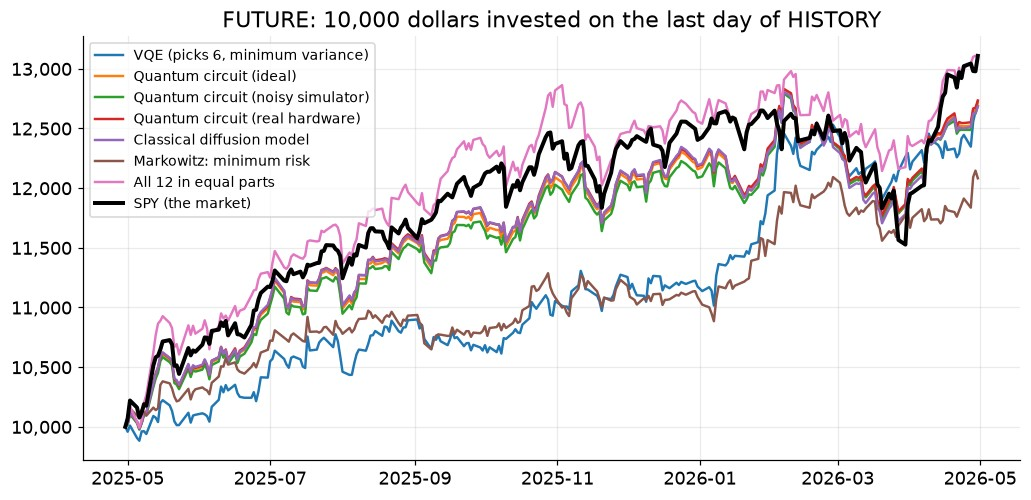

,return,annual volatility
Markowitz: minimum risk,+20.83%,9.57%
Quantum circuit (noisy simulator),+26.87%,10.72%
"VQE (picks 6, minimum variance)",+27.28%,10.96%
Quantum circuit (real hardware),+27.35%,11.00%
Quantum circuit (ideal),+27.16%,11.00%
Classical diffusion model,+26.85%,11.23%
SPY (the market),+31.08%,12.49%
All 12 in equal parts,+30.99%,12.83%


In [31]:
buy_price = prices.loc[:HISTORY[1]].iloc[-1]                       # we buy at the close of the last day of HISTORY
future_prices = prices.loc[FUTURE[0]:FUTURE[1]]

def evaluate(weights, columns=TICKERS):
    """Buy and hold. Returns the growth of 1 dollar and two measures."""
    value = (future_prices[columns] / buy_price[columns]) @ np.asarray(weights)
    value = pd.concat([pd.Series([1.0], index=[buy_price.name]), value])
    daily = value.pct_change().dropna()
    return value, {"return": value.iloc[-1] - 1, "annual volatility": daily.std() * np.sqrt(252)}

portfolios = {"VQE (picks 6, minimum variance)": w_vqe,
              "Quantum circuit (ideal)": w_quantum,
              "Quantum circuit (noisy simulator)": portfolio_from_risk_index(noisy_index)}
if hw_index is not None:
    portfolios["Quantum circuit (real hardware)"] = portfolio_from_risk_index(hw_index)
portfolios.update({"Classical diffusion model": w_classical, "Markowitz: minimum risk": w_min_risk,
                   "All 12 in equal parts": np.full(n, 1 / n)})

curves, rows = {}, {}
for portfolio_name, weights in portfolios.items():
    curves[portfolio_name], rows[portfolio_name] = evaluate(weights)
curves["SPY (the market)"], rows["SPY (the market)"] = evaluate([1.0], [BENCHMARK])

final_table = pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(11, 5))
for portfolio_name, curve in curves.items():
    is_market = portfolio_name.startswith("SPY")
    ax.plot(curve * 10_000, lw=2.6 if is_market else 1.6, color="black" if is_market else None, label=portfolio_name)
ax.set_title("FUTURE: 10,000 dollars invested on the last day of HISTORY"); ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")                             # 12500 is written 12,500
interactive_figure(fig)
final_table.sort_values("annual volatility").style.format("{:+.2%}", subset=["return"]).format("{:.2%}", subset=["annual volatility"])

**Summary of the class: Markowitz, VQE and the circuit, with the market as reference.** How they split the money and how they did on FUTURE, the 12 months after the construction window.

**All 12 go in.** The circuit received the 12 assets, one per qubit, measured an index for each one, and the portfolio weights them all by 1 / index: with the ibm_fez result, from highest to lowest weight, JPM, KO, BAC, PEP, AAPL, XOM, CVX, MSFT, AMZN, MELI, NVDA, TSLA. There is no cutoff: Tesla goes in with 2%. Markowitz, in contrast, leaves 4 assets at zero, and VQE picks 6 by construction.

In [32]:
circuit_name = "Quantum circuit (real hardware)" if hw_index is not None else "Quantum circuit (ideal)"
composition = pd.DataFrame({"Markowitz": w_min_risk, "VQE (picks 6, minimum variance)": w_vqe, "Quantum circuit": w_circuit}, index=TICKERS)
composition.loc["Total"] = composition.sum()
display(composition.style.format(lambda v: "" if abs(v) < 0.005 else f"{v:.0%}").set_properties(subset=pd.IndexSlice["Total", :], **{"font-weight": "bold"}).set_caption("Composition: how much goes to each asset"))

summary = final_table.loc[["Markowitz: minimum risk", "VQE (picks 6, minimum variance)", circuit_name, "SPY (the market)"]]
summary.index = ["Markowitz", "VQE (picks 6, minimum variance)", "Quantum circuit (all 12 weighted by 1 / index)", "SPY, the market"]
summary.style.format("{:+.2%}", subset=["return"]).format("{:.2%}", subset=["annual volatility"]).set_caption("Evaluation on FUTURE: the 12 months after the construction window")

,Markowitz,"VQE (picks 6, minimum variance)",Quantum circuit
AAPL,,,7%
MSFT,18%,,4%
AMZN,1%,13%,4%
NVDA,2%,,3%
TSLA,,,2%
MELI,,,4%
JPM,5%,11%,20%
BAC,,,14%
XOM,14%,17%,5%
CVX,2%,,4%


,return,annual volatility
Markowitz,+20.83%,9.57%
"VQE (picks 6, minimum variance)",+27.28%,10.96%
Quantum circuit (all 12 weighted by 1 / index),+27.35%,11.00%
"SPY, the market",+31.08%,12.49%


### Control test: does the circuit's ordering add anything?

The circuit's portfolio is "weight all 12 by 1 / index". To know how much of the result is the circuit's merit, we repeat **the same rule** with other numbers in place of the index: historical volatility, which is the exact classical analogue, and equal weights, which is using no number at all. We also add the rule we used before, picking the 6 lowest-index assets and allocating with minimum variance, so that the effect of the change can be seen.

In [33]:
control_index = hw_index if hw_index is not None else ideal_index
w_circuit_6 = minvar_weights([TICKERS[i] for i in np.argsort(control_index)[:6]])     # the previous rule, for comparison
control = pd.DataFrame({"The circuit: all 12 weighted by 1 / index": evaluate(w_circuit)[1],
                        "Classical analogue: all 12 weighted by 1 / historical volatility": evaluate(w_trivial)[1],
                        "All 12 in equal parts": evaluate(np.full(n, 1 / n))[1],
                        "Previous rule: 6 lowest-index, minimum variance": evaluate(w_circuit_6)[1]}).T
control.style.format("{:+.2%}", subset=["return"]).format("{:.2%}", subset=["annual volatility"])

,return,annual volatility
The circuit: all 12 weighted by 1 / index,+27.35%,11.00%
Classical analogue: all 12 weighted by 1 / historical volatility,+28.43%,10.29%
All 12 in equal parts,+30.99%,12.83%
"Previous rule: 6 lowest-index, minimum variance",+25.03%,11.30%


### Out-of-sample test: May to September 2026

FUTURE is no longer a pure test: we looked at it and then changed the portfolio rule. There are five later months, from April 30 to September 30, 2026, that were not used to build anything. We freeze the portfolios and evaluate them there. Transparency: this period was first looked at with the previous rule; the current rule, all 12 weighted by 1 / index, was adopted afterwards for a design reason, not a performance one, but it can no longer be called pure for that rule. It is five months: not much.

In [34]:
VALIDATION = ("2026-04-30", "2026-09-30")                # the five months after FUTURE, never consulted
VAL_COPY = DATA / "yahoo_prices_validation.csv"
try:
    import yfinance as yf
    stop = (pd.Timestamp(VALIDATION[1]) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    val_prices = yf.download(TICKERS + [BENCHMARK], start=VALIDATION[0], end=stop, auto_adjust=True, progress=False, threads=False)["Close"][TICKERS + [BENCHMARK]].dropna()
    assert len(val_prices) > 80, "incomplete download"
    if not VAL_COPY.exists():
        val_prices.to_csv(VAL_COPY)
    val_source = "Yahoo Finance (live download)"
except Exception as error:
    if not VAL_COPY.exists():
        raise RuntimeError("Could not download the validation data and there is no local copy") from error
    val_prices = pd.read_csv(VAL_COPY, index_col=0, parse_dates=True); val_source = "local copy"
print(f"Source: {val_source} | {len(val_prices)} trading days, from {val_prices.index[0].date()} to {val_prices.index[-1].date()}")

def evaluate_on(weights, period_prices, columns=TICKERS):
    """Buy at the first close of the period and hold until the last."""
    value = (period_prices[columns] / period_prices[columns].iloc[0]) @ np.asarray(weights)
    daily = value.pct_change().dropna()
    return {"return": value.iloc[-1] - 1, "annual volatility": daily.std() * np.sqrt(252)}

frozen = {"Markowitz: minimum risk": w_min_risk, "VQE (picks 6, minimum variance)": w_vqe, circuit_name + " (all 12 weighted by 1 / index)": w_circuit,
          "Classical diffusion model": w_classical, "Classical analogue: all 12 weighted by 1 / historical volatility": w_trivial, "Previous rule: 6 lowest-index, minimum variance": w_circuit_6}
validation = pd.DataFrame({label: evaluate_on(w, val_prices) for label, w in frozen.items()}).T
validation.loc["SPY (the market)"] = evaluate_on([1.0], val_prices, [BENCHMARK])
validation.sort_values("annual volatility").style.format("{:+.2%}", subset=["return"]).format("{:.2%}", subset=["annual volatility"]).set_caption("The five months after FUTURE: April 30 to September 30, 2026")

Source: Yahoo Finance (live download) | 106 trading days, from 2026-04-30 to 2026-09-30


,return,annual volatility
Classical analogue: all 12 weighted by 1 / historical volatility,+5.56%,10.01%
Quantum circuit (real hardware) (all 12 weighted by 1 / index),+4.56%,10.45%
Classical diffusion model,+4.90%,10.61%
"VQE (picks 6, minimum variance)",+0.05%,12.42%
SPY (the market),+6.66%,12.42%
"Previous rule: 6 lowest-index, minimum variance",+3.25%,12.74%
Markowitz: minimum risk,+8.87%,13.64%


**How to read the five-month test.** The classical analogue wins again: 10.0% against the circuit's 10.5%. Both beat the market, 12.4%, and Markowitz, 13.6%, which loses the edge it had on FUTURE; the circuit's previous rule, 12.7%, ends up worse than the current one. Five months are too few to conclude anything in anyone's favor; what they do show is that **no advantage is robust**: the ordering among methods changes from one period to the next. That is the honest conclusion of the class.

**How to read the tables, honestly**

- Compare the **volatility** of each portfolio with the market's (SPY): that is the goal of the method. Return is for reference.
- Markowitz, purely classical, achieves less risk than the circuit. And the control test says something stronger: with **the same rule**, weighting all 12 by 1 / historical volatility does better than weighting them by the circuit's index, 10.3% against 11.0%. In this sample, the circuit's ordering does not improve on the simplest classical ordering.
- VQE, picking 6 with minimum variance, ends up level with the circuit. So does the classical diffusion model, with the same rule as the circuit.
- One year of data is a single sample. It is not enough to draw strong conclusions, either for or against.

**Transparency about how the portfolio rule was reached.** The first version of this notebook picked the 6 lowest-index assets and weighted them by 1 / index. When evaluated, it gave 11.9% volatility. We moved to minimum variance among the 6 chosen **after** seeing that result: 11.3%. And then we moved to the current rule, all 12 weighted by 1 / index with no cutoff, for a design reason: that no number in the portfolio should be a decision of ours. On FUTURE that rule gives 11.0%. The three rules were evaluated on the same period, so no FUTURE figure is a pure out-of-sample test any more: they are exploratory results, and the reader has the right to know it.

**Three different results, which should not be mixed.**

1. **Quantum engineering: positive.** The 12-qubit and the 110-qubit circuits run on real hardware and preserve the risk ordering fairly well.
2. **Modeling: interesting, not superior.** The circuit produces a structure different from that of the classical model, and it can be studied experimentally.
3. **Financial: negative so far.** It beats neither Markowitz nor the simplest classical analogue, neither on FUTURE nor on the five months after.

**So is there quantum advantage?** No, and it has to be said clearly. This circuit can be simulated on a laptop, as we just did, and its risk ordering does not beat that of historical volatility. What the work does show:

1. That a 110-qubit circuit with real data **runs on current hardware** and can be validated against its ideal version.
2. A **three-way validation recipe** (ideal, hardware, classical) to separate "the model is different" from "the hardware is noisy", plus a **control test** with the same rule and another ordering, to separate "the circuit orders well" from "the rule does the work".
3. A **possible route to an algorithmic advantage**: reformulating the risk estimation to use this circuit inside *quantum amplitude estimation* (QAE), which in theory offers a quadratic improvement in the number of samples over the classical Monte Carlo method, under certain conditions. In practice it needs error-corrected computers.

## 9. Things to try next

1. **Change the assets.** In the configuration, replace a ticker (for example `"GGAL"` or `"YPF"`, which trade in New York) and run everything again.
2. **Move the contagion threshold.** With `contagion_map(corr, threshold=0.5)` more connections appear. What happens to the depth of the translated circuit?
3. **Try the full Hadamard mistake.** Build `risk_circuit(R_circuit, connections, hadamard=True)` and compare the risk ordering with the correct one.
4. **More knobs for VQE.** Add another layer to the `ansatz`. Does it find the best portfolio more often? How many more runs does it need?
5. **Real hardware.** Create your free IBM Quantum account, fill in the `.env` and set `RUN_ON_HARDWARE = True`.

### Further reading

- H. Markowitz, "Portfolio selection", *Journal of Finance*, 1952.
- A. Peruzzo et al., "A variational eigenvalue solver on a photonic quantum processor", *Nature Communications*, 2014 (VQE).
- E. Farhi, J. Goldstone and S. Gutmann, "A Quantum Approximate Optimization Algorithm", arXiv:1411.4028, 2014 (QAOA).
- S. Woerner and D. J. Egger, "Quantum risk analysis", *npj Quantum Information*, 2019 (amplitude estimation for risk).
- J. P. Braña, A. M. J. Litterio, A. Fernández et al., "A Parametric Quantum Circuit for Portfolio Risk Assessment at 110 Qubits", QCQSE-Chile, JCC 2026.
- Qiskit and IBM Quantum documentation: https://quantum.cloud.ibm.com/docs